# Data Preprocessing: Market Basket Dataset (AprioriMart)
Notebook ini memuat tahap pra-pemrosesan data (*Data Understanding & Preprocessing*) untuk dataset keranjang belanja (*Market Basket Analysis*).

* **Dataset:** `market_basket_dataset.csv`
* **Karakteristik Data:** 1.500 transaksi keranjang belanja dan 10 atribut produk ritel.
* **Fokus Analisis:**
  1. Pemeriksaan Dimensi Data (Jumlah Record & Atribut)
  2. Analisis Nilai Kosong (*Missing Value*) & Visualisasi Heatmap
  3. Penanganan Missing Value dengan Transformasi Matriks Biner (One-Hot Encoding)
  4. Analisis Data Duplikat Transaksi
  5. Deteksi Data Pencilan (*Outlier*) pada Ukuran Keranjang Belanja menggunakan Metode IQR dan Boxplot

### 1. Import Library
Memanggil library data science (pandas, numpy, matplotlib, seaborn).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### 2. Membaca Dataset
Memuat file CSV dataset keranjang belanja ke dalam DataFrame pandas.

In [2]:
df = pd.read_csv('market_basket_dataset.csv')

### 3. Menampilkan 5 Data Teratas (Head)
Melihat sampel 5 baris pertama data transaksi belanja.

In [3]:
df.head()

,Milk,Bread,Butter,Cheese,Eggs,Juice,Chips,Soda,Chicken,Apples
0,Milk,NaN,Butter,NaN,Eggs,Juice,Chips,Soda,NaN,Apples
1,NaN,NaN,Butter,NaN,NaN,Juice,Chips,NaN,NaN,Apples
2,Milk,NaN,NaN,NaN,NaN,Juice,NaN,Soda,NaN,Apples
3,NaN,NaN,Butter,NaN,Eggs,Juice,NaN,Soda,Chicken,NaN
4,NaN,Bread,Butter,NaN,Eggs,Juice,Chips,NaN,NaN,Apples


### 4. Menampilkan 5 Data Terbawah (Tail)
Melihat sampel 5 baris terakhir data transaksi belanja.

In [4]:
df.tail()

,Milk,Bread,Butter,Cheese,Eggs,Juice,Chips,Soda,Chicken,Apples
1495,NaN,NaN,NaN,NaN,Eggs,Juice,NaN,NaN,NaN,NaN
1496,Milk,NaN,NaN,NaN,Eggs,NaN,Chips,NaN,NaN,NaN
1497,NaN,NaN,NaN,Cheese,Eggs,NaN,Chips,Soda,Chicken,NaN
1498,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1499,Milk,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Chicken,NaN


### 5. Jumlah Baris (Record)
Menghitung total baris transaksi dalam dataset.

In [5]:
print("Jumlah Baris:", df.shape[0])

Jumlah Baris: 1500


### 6. Jumlah Kolom (Atribut)
Menghitung total atribut produk ritel.

In [6]:
print("Jumlah Kolom:", df.shape[1])

Jumlah Kolom: 10


### 7. Cek Tipe Data & Struktur Kolom
Memeriksa tipe data masing-masing kolom dan penggunaan memori.

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Milk     635 non-null    str  
 1   Bread    622 non-null    str  
 2   Butter   647 non-null    str  
 3   Cheese   623 non-null    str  
 4   Eggs     643 non-null    str  
 5   Juice    636 non-null    str  
 6   Chips    657 non-null    str  
 7   Soda     634 non-null    str  
 8   Chicken  606 non-null    str  
 9   Apples   627 non-null    str  
dtypes: str(10)
memory usage: 117.3 KB


### 8. Cek Missing Value per Kolom
Mendeteksi jumlah nilai kosong (produk tidak dibeli) pada setiap kolom produk.

In [8]:
df.isna().sum()

Milk       865
Bread      878
Butter     853
Cheese     877
Eggs       857
Juice      864
Chips      843
Soda       866
Chicken    894
Apples     873
dtype: int64

### 9. Total Missing Value Keseluruhan
Menghitung akumulasi seluruh nilai kosong di seluruh data.

In [9]:
print("Total Missing Value:", df.isna().sum().sum())

Total Missing Value: 8670


### 10. Persentase Missing Value (%)
Menghitung persentase rasio nilai kosong terhadap total baris transaksi.

In [10]:
(df.isna().sum() / len(df) * 100).round(2)

Milk       57.67
Bread      58.53
Butter     56.87
Cheese     58.47
Eggs       57.13
Juice      57.60
Chips      56.20
Soda       57.73
Chicken    59.60
Apples     58.20
dtype: float64

### 11. Visualisasi Heatmap Missing Value
Menampilkan sebaran visual nilai kosong pada keranjang belanja sebelum transformasi.

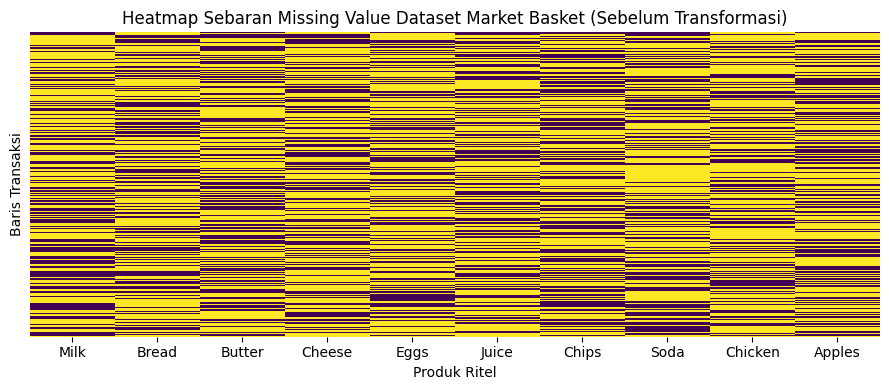

In [11]:
plt.figure(figsize=(9, 4))
sns.heatmap(df.isna(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Heatmap Sebaran Missing Value Dataset Market Basket (Sebelum Transformasi)')
plt.xlabel('Produk Ritel')
plt.ylabel('Baris Transaksi')
plt.tight_layout()
plt.show()

### 12. Penanganan Missing Value: Transformasi Matriks Biner (One-Hot Encoding)
Mengubah nilai produk yang dibeli menjadi 1 dan produk yang tidak dibeli (NaN) menjadi 0.

In [12]:
df_biner = df.notna().astype(int)
df_biner.head()

,Milk,Bread,Butter,Cheese,Eggs,Juice,Chips,Soda,Chicken,Apples
0,1,0,1,0,1,1,1,1,0,1
1,0,0,1,0,0,1,1,0,0,1
2,1,0,0,0,0,1,0,1,0,1
3,0,0,1,0,1,1,0,1,1,0
4,0,1,1,0,1,1,1,0,0,1


### 13. Verifikasi Missing Value Setelah Transformasi Biner
Memeriksa kembali nilai kosong untuk memastikan data telah bersih menjadi biner (0 dan 1).

In [13]:
print("Total Missing Value Setelah Transformasi:", df_biner.isna().sum().sum())

Total Missing Value Setelah Transformasi: 0


### 14. Cek Jumlah Duplikat Transaksi
Menghitung baris transaksi dengan kombinasi belanja barang yang identik.

In [14]:
print("Jumlah Duplikat Penuh:", df.duplicated().sum())

Jumlah Duplikat Penuh: 774


### 15. Hitung Ukuran Keranjang Belanja per Transaksi
Menghitung jumlah produk yang dibeli dalam setiap transaksi (banyak item per baris).

In [15]:
item_per_transaksi = df.notna().sum(axis=1)

### 16. Statistik Deskriptif Ukuran Keranjang Belanja
Menganalisis nilai rata-rata, standar deviasi, nilai minimum, median, dan maksimum belanja.

In [16]:
item_per_transaksi.describe()

count    1500.000000
mean        4.220000
std         1.560734
min         0.000000
25%         3.000000
50%         4.000000
75%         5.000000
max         9.000000
dtype: float64

### 17. Visualisasi Boxplot Ukuran Keranjang Belanja
Menampilkan sebaran distribusi ukuran belanja dan titik pencilan (outlier).

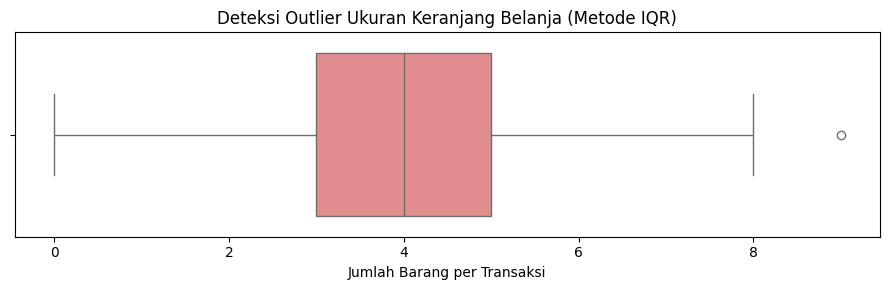

In [17]:
plt.figure(figsize=(9, 3))
sns.boxplot(x=item_per_transaksi, color='lightcoral')
plt.title('Deteksi Outlier Ukuran Keranjang Belanja (Metode IQR)')
plt.xlabel('Jumlah Barang per Transaksi')
plt.tight_layout()
plt.show()

### 18. Perhitungan Kuartil (Q1, Q3) dan Interquartile Range (IQR)
Menghitung kuartil bawah (Q1), kuartil atas (Q3), dan rentang antarkuartil (IQR).

In [18]:
Q1 = item_per_transaksi.quantile(0.25)
Q3 = item_per_transaksi.quantile(0.75)
IQR = Q3 - Q1
print("Q1 (Kuartil 1):", Q1)
print("Q3 (Kuartil 3):", Q3)
print("IQR (Rentang Antarkuartil):", IQR)

Q1 (Kuartil 1): 3.0
Q3 (Kuartil 3): 5.0
IQR (Rentang Antarkuartil): 2.0


### 19. Perhitungan Batas Atas Outlier (Tukey Rule)
Menentukan batas ambang batas atas untuk mengklasifikasikan transaksi outlier.

In [19]:
batas_atas = Q3 + 1.5 * IQR
print("Batas Atas Outlier:", batas_atas)

Batas Atas Outlier: 8.0


### 20. Jumlah Transaksi Terdeteksi Outlier
Menghitung total transaksi yang melampaui batas atas IQR.

In [20]:
outliers = item_per_transaksi[item_per_transaksi > batas_atas]
print("Jumlah Transaksi Outlier:", len(outliers))

Jumlah Transaksi Outlier: 1


### 21. Daftar Transaksi Outlier Terbesar
Menampilkan transaksi belanja dengan jumlah item produk tertinggi.

In [21]:
outliers.sort_values(ascending=False).head(10)

875    9
dtype: int64